# spatialmirif: MIR MinMax, explicit rotation, NRRD → Zarr roundtrip

In [1]:
from pathlib import Path
from pprint import pprint

import matplotlib.pyplot as plt
import numpy as np
import spatialmirif as mi

from data_path import (
    data_path_zarr_S1_N2,
    data_path_zarr_S1_N2_info,
)

print("spatialmirif:", mi.__file__)

spatialmirif: D:\Project_Cemos\pymirifimaging\spatialmirif\spatialmirif\__init__.py


In [3]:
# Select the MIR band and an explicit export rotation (multiples of 90°).
requested_wavenumber = 1650.0
rotation_degrees = 0  # 90 = CCW, -90 = CW, 180 = half-turn

# None for 2D MIR; specify measured Z spacing (µm) only when needed.
pz_um = 10.0

print("Requested wavenumber:", requested_wavenumber)
print("Export rotation:", rotation_degrees, "degrees")

Requested wavenumber: 1650.0
Export rotation: 0 degrees


In [4]:
# Load raw MIR Zarr; the reader initializes SpatialData and Dask.
I = mi.ZarrSpectrumReader(
    data_path_zarr_S1_N2,
    info_path=data_path_zarr_S1_N2_info,
    pz=pz_um,
)

I.SetNormalization("None")
I.SetSpectralSelection("Nearest")
I.SetPooling("None")
I.SetImageNormalization("None")

I.info()
print("Dask cube:", I.GetCube(lazy=True).shape)
print("SpatialData images:", list(I.GetSpatialData().images))

measured_wavenumber = I.GetNearestWavenumber(requested_wavenumber)
raw_spacing = np.asarray(I.GetSpacing(), dtype=float)
raw_origin = np.asarray(I.GetOrigin(), dtype=float)
raw_direction = np.asarray(I.GetDirection(), dtype=float)

image_before = I.GetArray(
    requested_wavenumber,
    selection="Nearest",
    squeeze=True,
)

print("Measured wavenumber:", measured_wavenumber)
print("Raw intensity range:", float(np.nanmin(image_before)),
      "to", float(np.nanmax(image_before)))

c:\Users\arsla\anaconda3\envs\spatialmirif-dev\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



spatialmirif — Dataset Information
---------------------------------------------
Name               : 0
Source             : D:\Project_Cemos\with_pymir\Slide_1\S1_N2\0.zarr
Modality           : MIR
Spectrum type      : ContinuousProfile
Dimensions         : [1560, 2400,    1]
Pixel spacing      : [0.004338, 0.004338, 0.01    ] mm
Origin             : [0., 0., 0.] mm
Direction          : [1., 0., 0., 0., 1., 0., 0., 0., 1.]
Spectra            : 3744000
Spectral bins      : 213
Wavenumber range   : 954.00 to 1802.00 cm^-1
First 10 wavenumbers: [954., 958., 962., 966., 970., 974., 978., 982., 986., 990.]
Intensity dtype    : float32
Storage            : SpatialData + Dask
Dask cube: (2400, 1560, 213)
SpatialData images: ['mir_raw']
Measured wavenumber: 1650.0
Raw intensity range: -0.10895702242851257 to 1.5398935079574585


normalization=None, pooling=None, image_normalization=MinMax, spectral_selection=Nearest, tolerance=0
Processed range: 0.0 to 1.0


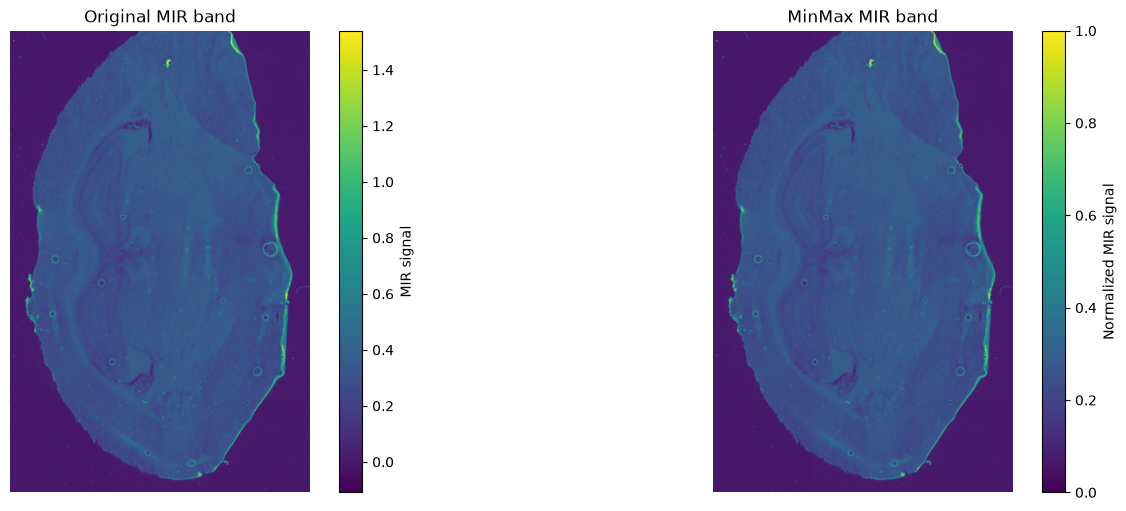

In [5]:
# Apply image-level MinMax normalization; spectra remain unnormalized.
I.SetImageNormalization("MinMax")
image_processed = I.GetArray(
    requested_wavenumber,
    selection="Nearest",
    squeeze=True,
)

print(I.GetParametersAsFormattedString())
print("Processed range:", float(np.nanmin(image_processed)),
      "to", float(np.nanmax(image_processed)))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for ax, image, title, unit in zip(
    axes,
    (image_before, image_processed),
    ("Original MIR band", "MinMax MIR band"),
    ("MIR signal", "Normalized MIR signal"),
):
    im = ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")
    fig.colorbar(im, ax=ax, label=unit)
plt.show()


In [6]:
# Export one selected band to NRRD; rotation is never inferred.
rotation_tag = str(rotation_degrees).replace("-", "m")
output_nrrd = (
    Path(data_path_zarr_S1_N2).parent
    / f"MIR_{measured_wavenumber:g}cm-1_MinMax_rot{rotation_tag}.nrrd"
)

I.WriteNRRD(
    output_nrrd,
    wavenumbers=[requested_wavenumber],
    selection="Nearest",
    rotate=rotation_degrees,
)
print("Saved:", output_nrrd)


Saved: D:\Project_Cemos\with_pymir\Slide_1\S1_N2\MIR_1650cm-1_MinMax_rot0.nrrd


In [7]:
# Reopen NRRD and construct the expected pixel rotation.
N = mi.NRRDSpectrumReader(output_nrrd)
image_nrrd = N.GetArray(
    measured_wavenumber,
    selection="Exact",
    squeeze=True,
)
nrrd_metadata = N.GetMetaData()

rotation_k = (rotation_degrees // 90) % 4
expected_nrrd_image = np.rot90(image_processed, k=rotation_k)
expected_nrrd_spacing = raw_spacing.copy()
if rotation_k in (1, 3) and expected_nrrd_spacing.size >= 2:
    expected_nrrd_spacing[[0, 1]] = expected_nrrd_spacing[[1, 0]]

# This export rotates pixels and swaps X/Y spacing, but does not rotate
# physical origin/direction for quarter turns.
print("NRRD image:", image_nrrd.shape)
print("Expected image:", expected_nrrd_image.shape)

NRRD image: (2400, 1560)
Expected image: (2400, 1560)


In [8]:
# Validate source Zarr → NRRD, including selected wavenumber and spacing.
checks_nrrd = {
    "image values": np.allclose(image_nrrd, expected_nrrd_image, equal_nan=True),
    "wavenumber": np.allclose(N.GetXAxis(), [measured_wavenumber]),
    "spacing": np.allclose(
        N.GetSpacing(),
        expected_nrrd_spacing[:len(N.GetSpacing())],
    ),
}

N.info()
for name, passed in checks_nrrd.items():
    print(f"{name:20s}: {passed}")

print("Export rotation metadata:", nrrd_metadata.get(
    "spatialmirif.export.rotation_degrees", "<missing>"
))
print("Processing metadata:")
pprint({k: v for k, v in nrrd_metadata.items() if "processing" in k.lower()})
assert all(checks_nrrd.values()), checks_nrrd


spatialmirif — Dataset Information
---------------------------------------------
Name               : MIR_1650cm-1_MinMax_rot0
Source             : D:\Project_Cemos\with_pymir\Slide_1\S1_N2\MIR_1650cm-1_MinMax_rot0.nrrd
Modality           : MIR
Spectrum type      : ContinuousProfile
Dimensions         : [1560, 2400,    1]
Pixel spacing      : [0.004338, 0.004338, 0.01    ] mm
Origin             : [0., 0., 0.] mm
Direction          : [1., 0., 0., 0., 1., 0., 0., 0., 1.]
Spectra            : 3744000
Spectral bins      : 1
Wavenumber range   : 1650.00 to 1650.00 cm^-1
First 10 wavenumbers: [1650.]
Intensity dtype    : float32
Storage            : SpatialData + Dask
image values        : True
wavenumber          : True
spacing             : True
Export rotation metadata: 0
Processing metadata:
{'spatialmirif.processing.image_normalization': 'MinMax',
 'spatialmirif.processing.normalization': 'None',
 'spatialmirif.processing.pooling': 'None',
 'spatialmirif.processing.spectral_selection':

In [9]:
# Save NRRD as a raw MIR Zarr store (hypercube + wvnm).
roundtrip_zarr = output_nrrd.parent / f"{output_nrrd.stem}_from_nrrd.zarr"
N.WriteZarr(roundtrip_zarr, overwrite=True)
print("Saved:", roundtrip_zarr)

Saved: D:\Project_Cemos\with_pymir\Slide_1\S1_N2\MIR_1650cm-1_MinMax_rot0_from_nrrd.zarr


In [10]:
# Reopen Zarr and verify the NRRD roundtrip.
R = mi.ZarrSpectrumReader(roundtrip_zarr)
image_roundtrip = R.GetArray(
    measured_wavenumber,
    selection="Exact",
    squeeze=True,
)
roundtrip_metadata = R.GetMetaData()

checks_zarr = {
    "image values": np.allclose(image_roundtrip, image_nrrd, equal_nan=True),
    "wavenumber": np.allclose(R.GetXAxis(), N.GetXAxis()),
    "spacing": np.allclose(R.GetSpacing(), N.GetSpacing()),
    "origin": np.allclose(R.GetOrigin(), N.GetOrigin()),
    "direction": np.allclose(R.GetDirection(), N.GetDirection()),
}

R.info()
for name, passed in checks_zarr.items():
    print(f"{name:20s}: {passed}")

print("Processing / rotation metadata:")
pprint({
    k: v
    for k, v in roundtrip_metadata.get("source_metadata", {}).items()
    if "processing" in k.lower() or "rotation" in k.lower()
})
assert all(checks_zarr.values()), checks_zarr


spatialmirif — Dataset Information
---------------------------------------------
Name               : MIR_1650cm-1_MinMax_rot0_from_nrrd
Source             : D:\Project_Cemos\with_pymir\Slide_1\S1_N2\MIR_1650cm-1_MinMax_rot0_from_nrrd.zarr
Modality           : MIR
Spectrum type      : ContinuousProfile
Dimensions         : [1560, 2400,    1]
Pixel spacing      : [0.004338, 0.004338, 0.01    ] mm
Origin             : [0., 0., 0.] mm
Direction          : [1., 0., 0., 0., 1., 0., 0., 0., 1.]
Spectra            : 3744000
Spectral bins      : 1
Wavenumber range   : 1650.00 to 1650.00 cm^-1
First 10 wavenumbers: [1650.]
Intensity dtype    : float32
Storage            : SpatialData + Dask
image values        : True
wavenumber          : True
spacing             : True
origin              : True
direction           : True
Processing / rotation metadata:
{'spatialmirif.export.rotation_degrees': '0',
 'spatialmirif.processing.image_normalization': 'MinMax',
 'spatialmirif.processing.normalizati

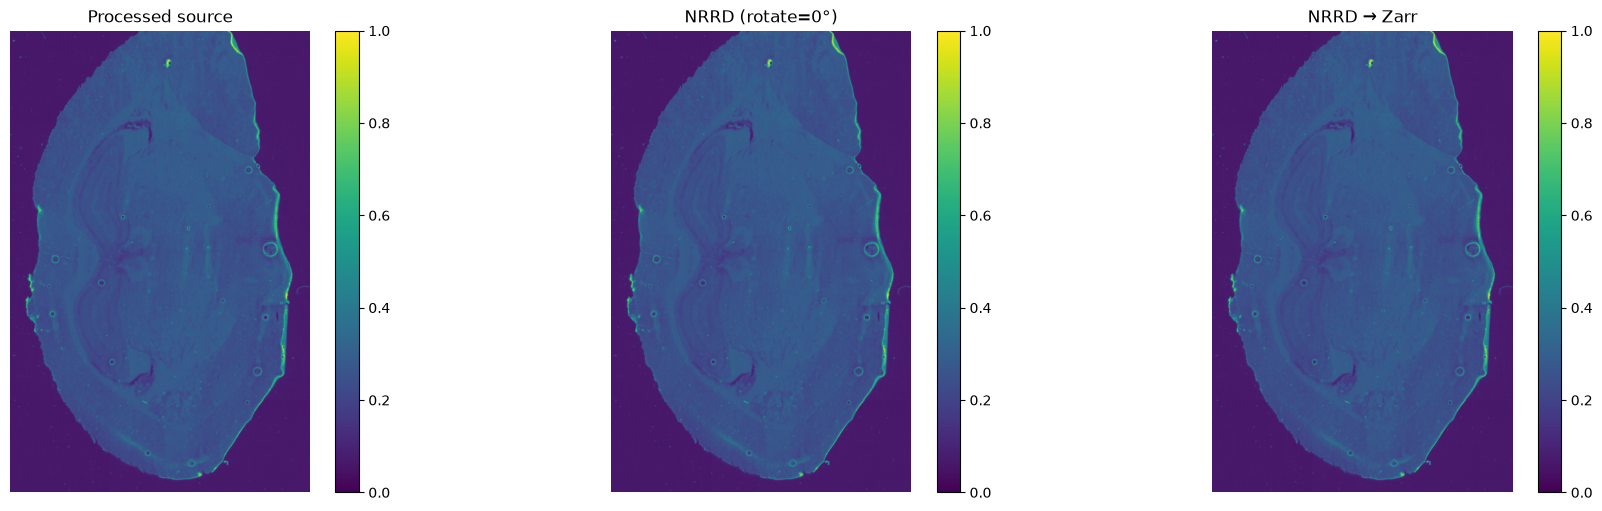

In [11]:
# Compare processed MIR, exported NRRD, and reimported Zarr.
fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
for ax, image, title in zip(
    axes,
    (image_processed, image_nrrd, image_roundtrip),
    ("Processed source", f"NRRD (rotate={rotation_degrees}°)", "NRRD → Zarr"),
):
    im = ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")
    fig.colorbar(im, ax=ax)
plt.show()